### Univariate and Bivariate Analysis

#### Importing liabriries and dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "E:\\OneDrive\\Desktop\\Istiyaque_Kamil\\Courses\\Data Analytics\\My Projects\\P1- E-Commerce Sales Analysis\\Data\\Ecommerce_sales_cleaned.csv"
)
# Coverting data types
df["order_date"]= pd.to_datetime(df["order_date"], format="mixed" )
df["ship_date"]= pd.to_datetime(df["ship_date"], format="mixed")

#### Display settings

In [2]:

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

#### PART A — BASIC DATA OVERVIEW


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns: ")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Rows: 10194
Columns: 21

Columns: 
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country_region', 'city', 'state_province', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Data Types:
row_id                     int64
order_id                     str
order_date        datetime64[us]
ship_date         datetime64[us]
ship_mode                    str
customer_id                  str
customer_name                str
segment                      str
country_region               str
city                         str
state_province               str
postal_code                  str
region                       str
product_id                   str
category                     str
sub-category                 str
product_name                 str
sales                    float64
quantity                   int64
discount                 float64
profit          

#### PART B — NUMERICAL SUMMARY

In [4]:
numeric_columns = [
    "sales",
    "quantity",
    "discount",
    "profit"
]

print (df[numeric_columns].describe())

          sales  quantity  discount    profit
count 10,194.00 10,194.00 10,194.00 10,194.00
mean     228.23      3.79      0.16     28.67
std      619.91      2.23      0.21    232.47
min        0.44      1.00      0.00 -6,599.98
25%       17.22      2.00      0.00      1.76
50%       53.91      3.00      0.20      8.69
75%      209.50      5.00      0.20     29.30
max   22,638.48     14.00      0.80  8,399.98


#### PART C — UNIQUE COUNTS

In [5]:
unique_summary = {
    "Orders": df["order_id"].nunique(),
    "Customers": df["customer_id"].nunique(),
    "Prodoucts": df["product_id"].nunique(),
    "Categories": df["category"].nunique(),
    "Sub Categories": df["sub-category"].nunique(),
    "Regions": df["region"].nunique(),
    "Segments": df["segment"].nunique(),
    "Ship Modes": df["ship_mode"].nunique()
}

for key, value in unique_summary.items():
    print(f"{key}: {value}")
        
    

Orders: 5111
Customers: 804
Prodoucts: 1862
Categories: 3
Sub Categories: 17
Regions: 4
Segments: 3
Ship Modes: 4


#### PART D — UNIVARIATE ANALYSIS
##### SALES DISTRIBUTION

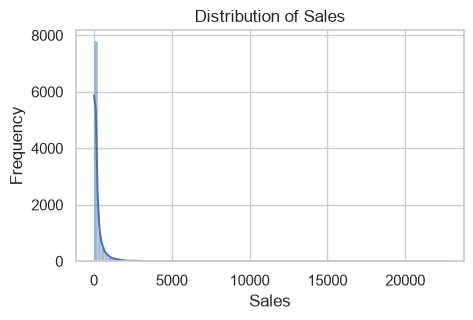

In [6]:
plt.figure(figsize=(5,3))

sns.histplot(
    data=df,
    x="sales",
    bins=100,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

#### PROFIT DISTRIBUTION

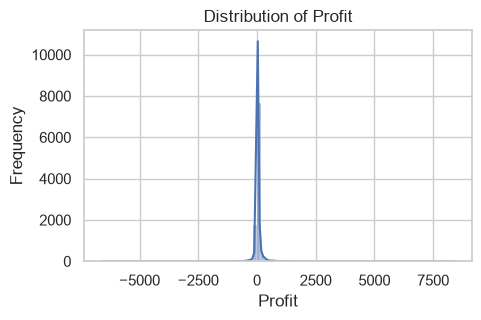

In [7]:
plt.figure(figsize=(5,3))

sns.histplot(
    data=df,
    x="profit",
    bins=100,
    kde=True
)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()


#### QUANTITY DISTRIBUTION

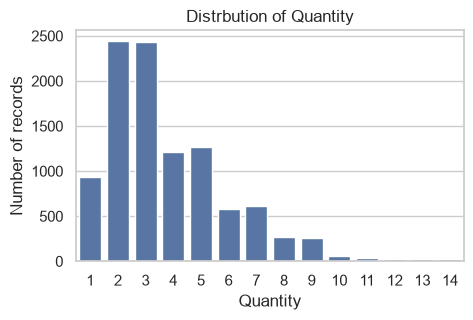

In [8]:
plt.figure(figsize=(5,3))

sns.countplot(
    data=df,
    x="quantity"
)

plt.title("Distrbution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Number of records")
plt.show()

#### DISCOUNT DISTRIBUTION


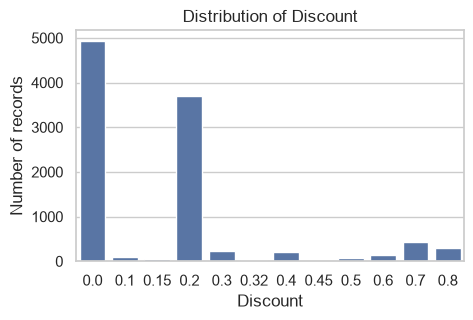

In [9]:
plt.figure(figsize=(5,3))

sns.countplot(
    data=df,
    x="discount"
)

plt.title("Distribution of Discount")
plt.xlabel("Discount")
plt.ylabel("Number of records")
plt.show()

### PART E — CATEGORICAL DISTRIBUTIONS


#### Category


 Category Distribution:
category
Office Supplies    6128
Furniture          2201
Technology         1865
Name: count, dtype: int64


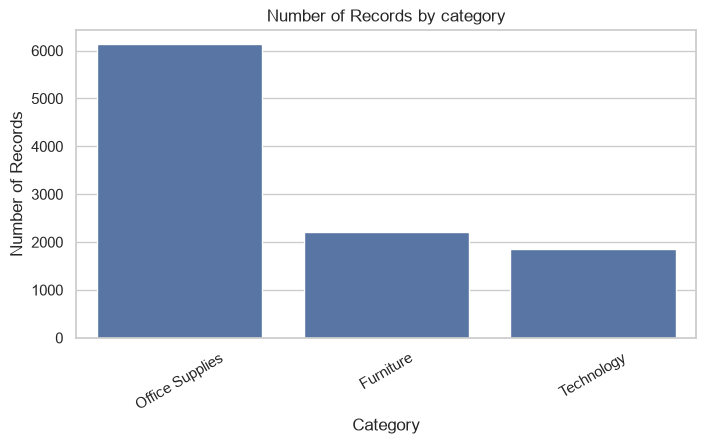

In [10]:
category_count= df["category"].value_counts()

print("\n Category Distribution:")
print(category_count)

plt.figure(figsize=(8,4))


sns.countplot(
    data=df,
    x="category",
    order=category_count.index
)

plt.title("Number of Records by category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

#### Region


Region Distribution
region
West       3253
East       2986
Central    2335
South      1620
Name: count, dtype: int64


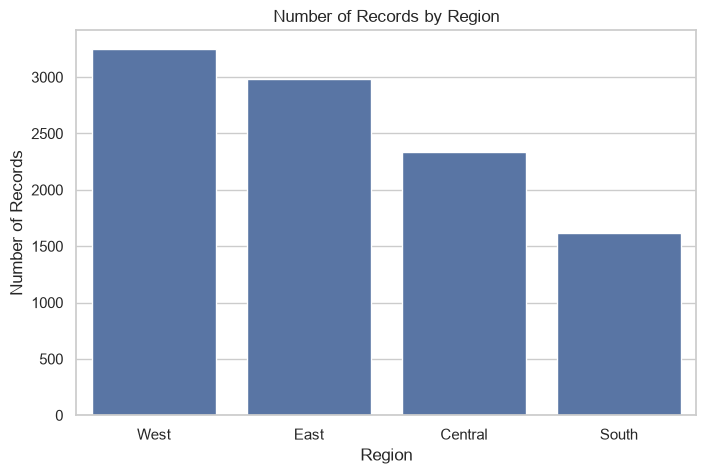

In [11]:
region_count= df["region"].value_counts()

print("\nRegion Distribution")
print(region_count)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="region",
    order=region_count.index
)

plt.title("Number of Records by Region")
plt.xlabel("Region")
plt.ylabel("Number of Records")
plt.show()


#### Segment


 Segment Distribution: 
segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64


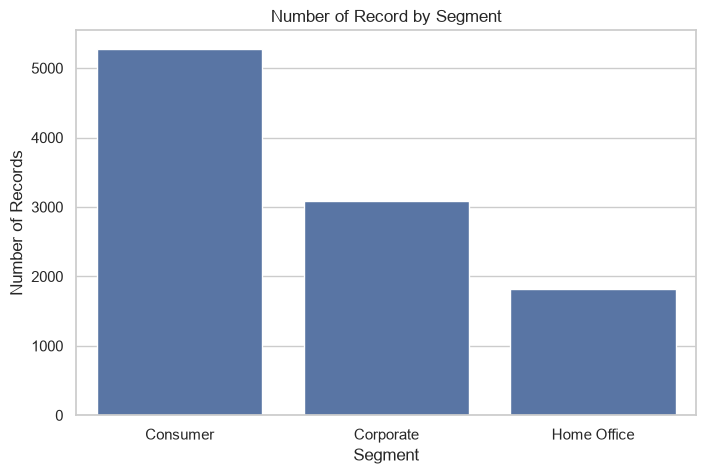

In [12]:
segment_count= df["segment"].value_counts()

print("\n Segment Distribution: ")
print(segment_count)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="segment",
    order=segment_count.index
)

plt.title("Number of Record by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Records")
plt.show()

#### Ship Mode


Ship_Mode_Distribution
ship_mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64


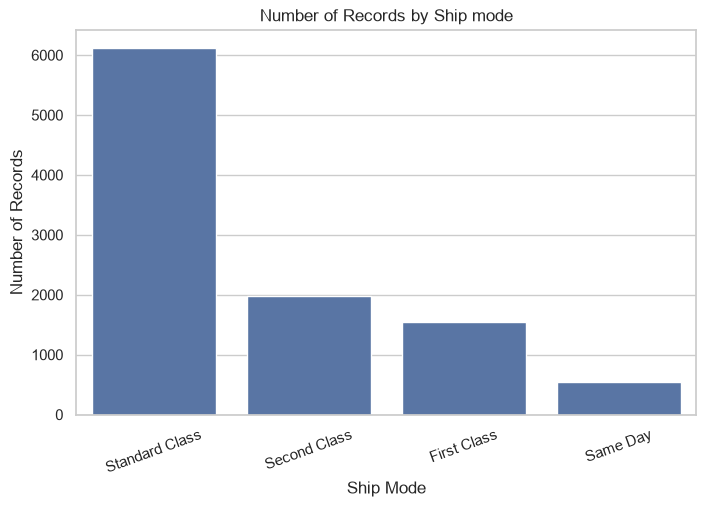

In [13]:
ship_mode_count=df["ship_mode"].value_counts()
print("\nShip_Mode_Distribution")
print(ship_mode_count)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="ship_mode",
    order=ship_mode_count.index
)

plt.title("Number of Records by Ship mode")
plt.xlabel("Ship Mode")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.show()

         

### PART F — SALES & PROFIT BY CATEGORY


In [14]:
category_performance = (
    df.groupby("category")
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        orders=("order_id", "nunique")
)
    .sort_values("sales", ascending=False)
)

category_performance.head()

,sales,profit,quantity,orders
category,,,,
Technology,"839,893.28","146,543.38",7017,1560
Furniture,"754,747.76","19,730.00",8369,1819
Office Supplies,"731,893.31","126,023.44",23268,3812


#### Sales by Category

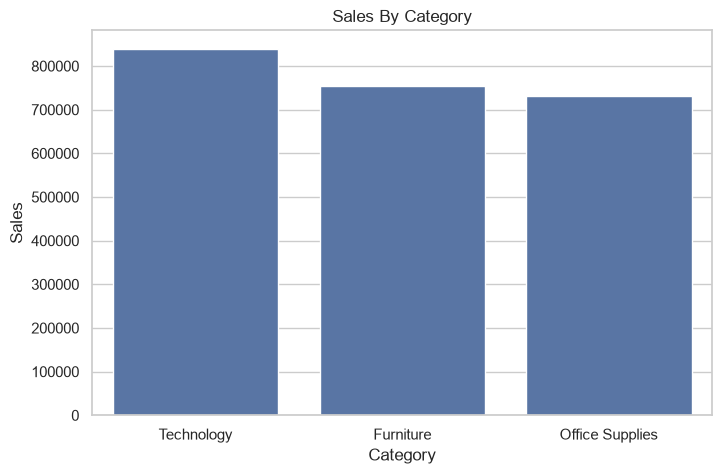

In [15]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=category_performance.reset_index(),
    x="category",
    y="sales"
)

plt.title("Sales By Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()

#### Profit by Category

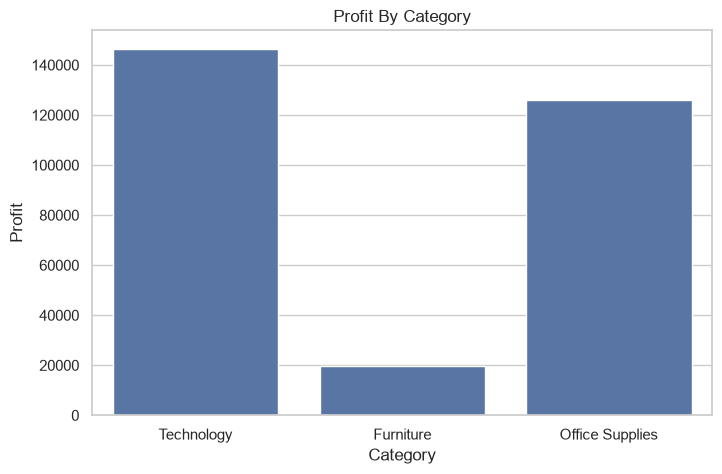

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=category_performance.reset_index(),
    x="category",
    y="profit"
)

plt.title("Profit By Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.show()

### PART G — SALES & PROFIT BY REGION

In [17]:
region_performance=(
    df.groupby("region")
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        quantity=("quantity","sum"),
        order=("order_id", "nunique")
    )
    .sort_values("sales", ascending=False)
)

print("\nSales and Profit by Region")
print(region_performance)


Sales and Profit by Region
             sales     profit  quantity  order
region                                        
West    739,813.61 110,798.82     12466   1635
East    691,828.17  94,883.26     11159   1475
Central 503,170.67  39,865.31      8820   1179
South   391,721.91  46,749.43      6209    822


### PART H — SALES & PROFIT BY SEGMENT

In [18]:
segment_performance=(
    df.groupby("segment")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        quantity=("quantity", "sum"),
        order=("order_id", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

print("\nSales and Profit by Segment")
print(segment_performance)
        
    


Sales and Profit by Segment
                   Sales     Profit  quantity  order
segment                                             
Consumer    1,170,659.79 136,371.45     19844   2628
Corporate     715,806.13  94,249.64     11898   1552
Home Office   440,068.43  61,675.73      6912    931


### PART I — TOP SUB-CATEGORIES

In [19]:
subcategory_performance=(
    df.groupby("sub-category")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum"),
        Orders=("order_id", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

print("\nTop Sub-Category")
print(subcategory_performance)


Top Sub-Category
                  Sales     Profit  Quantity  Orders
sub-category                                        
Chairs       335,768.25  27,223.53      2431     591
Phones       331,842.64  45,050.83      3357     826
Storage      224,644.55  21,285.11      3191     787
Tables       208,020.18 -17,753.21      1261     314
Binders      207,354.88  31,426.10      6071    1339
Machines     189,925.03   3,461.98       442     114
Accessories  167,380.32  41,936.64      2976     718
Copiers      150,745.29  56,093.94       242      70
Bookcases    115,361.20  -3,632.07       878     228
Appliances   108,213.18  18,329.48      1750     459
Furnishings   95,598.13  13,891.74      3799     919
Paper         79,540.54  34,511.51      5207    1205
Supplies      46,725.50  -1,171.39       653     189
Art           27,659.01   6,653.20      3092     756
Envelopes     16,528.36   6,988.02       914     251
Labels        12,695.04   5,572.78      1410     348
Fasteners      8,532.24   2,

#### Top 10 by Sales

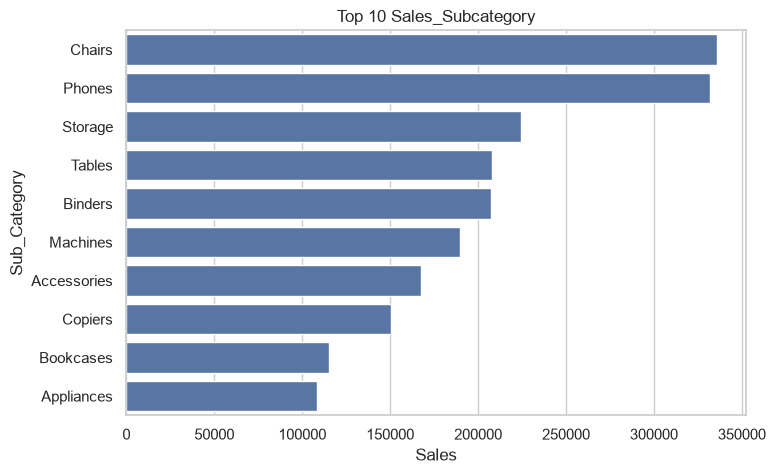

In [20]:
top10_sales_subcategory=(
    subcategory_performance
    .sort_values("Sales",ascending=False)
    .head(10)
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=top10_sales_subcategory.reset_index(),
    x="Sales",
    y="sub-category"
)

plt.title("Top 10 Sales_Subcategory")
plt.xlabel("Sales")
plt.ylabel("Sub_Category")    
plt.show()

#### Top 10 by Profit

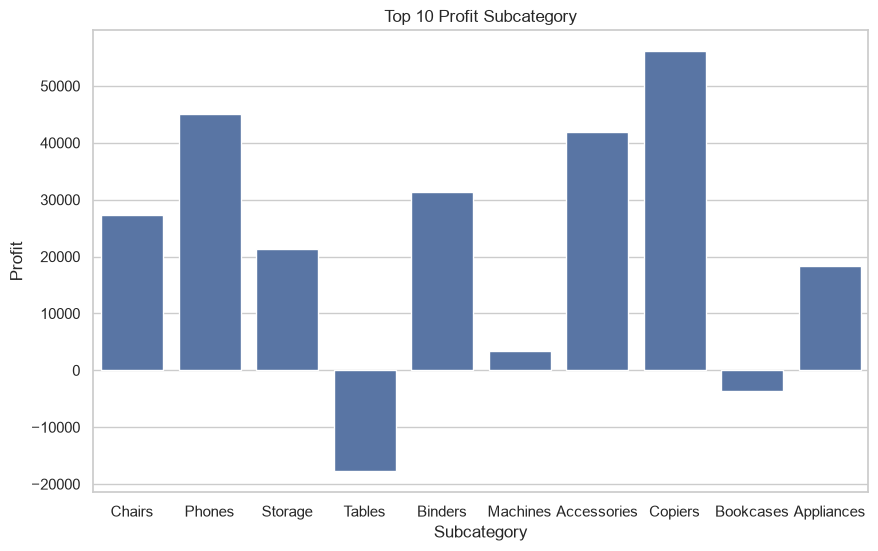

In [21]:
top10_profit_subcategory=(
    subcategory_performance
    .sort_values("Sales", ascending=False)
    .head(10)    
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_profit_subcategory.reset_index(),
    x="sub-category",
    y="Profit"
)

plt.title("Top 10 Profit Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Profit")
plt.show()


### PART J — SALES VS PROFIT

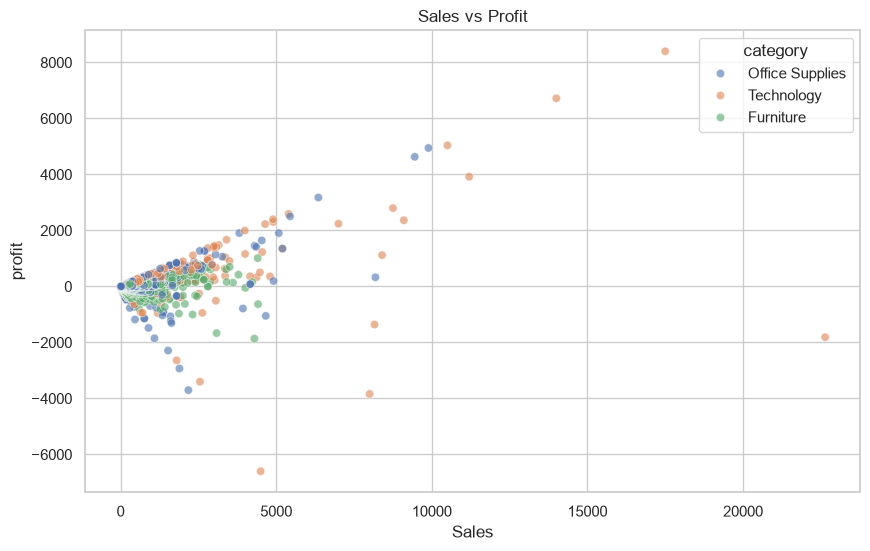

In [22]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="sales",
    y="profit",
    hue="category",
    alpha=0.6
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("profit")
plt.show()

#### PART K — DISCOUNT VS PROFIT

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    hue="category",
    alpha=0.6
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

#### PART L — DISCOUNT VS SALES

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="discount",
    y="sales",
    hue="category",
    alpha=0.9
)

plt.title("Discount vs Sales")
plt.xlabel("Discount")
plt.ylabel("Sales")
plt.show()

#### PART M — QUANTITY VS SALES

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="quantity",
    y="sales",
    hue="category",
    alpha=1
)

plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

#### PART N — CORRELATION MATRIX

In [ ]:
correlation_matrix=df[
    ["sales","quantity","discount","profit"]
].corr()

print("\nCorrelation Matrix: ")
print(correlation_matrix)

plt.figure(figsize=(10,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation_Matrix")
plt.show()

#### PART O — TIME-BASED ANALYSIS

In [ ]:
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.month_name()
df["order_year_month"] = df["order_date"].dt.to_period("M")

monthly_performance = (
    df.groupby("order_year_month")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum"),
        Order=("order_id", "nunique")    
    )
    .reset_index()
)

monthly_performance["order_year_month"]= (
    monthly_performance["order_year_month"].astype(str)
)

print("\nMonthly Performance")

print(monthly_performance)

#### Monthly Sales Trend

In [ ]:
plt.figure(figsize=(14,6))

sns.lineplot(
    data=monthly_performance,
    x="order_year_month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.show()

####  Monthly Profit Trend

In [ ]:
plt.figure(figsize=(14,6))

sns.lineplot(
    data=monthly_performance,
    x="order_year_month",
    y="Profit",
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=90)
plt.show()


### PART P — PROFIT MARGIN


In [ ]:
total_sales = df ["sales"].sum()
total_profit = df ["profit"].sum()

overall_profit_margin = (
    total_profit/total_sales
) *100

print("\nOverall Sales:", total_sales)
print("\nOverall Profit", total_profit)
print("Overall Profit Margin:", overall_profit_margin, "%")


#### Category Profit Margin

In [ ]:
category_margin=(
    df.groupby("category")
    .agg(
        sales=("sales", "sum"),
        profit=("profit", "sum")
    )       
)

category_margin["profit_margin"] = (
    category_margin["profit"]
    / category_margin["sales"]
) *100

print("\nCategory Profit Margin:")
print(category_margin.sort_values("profit_margin",ascending=False))

### PART Q — LOSS-MAKING RECORDS


In [ ]:
loss_records = df[df["profit"] < 0]
print("\nLoss_making records:", len(loss_records))

loss_by_category = (
    loss_records
    .groupby("category")
    .agg(
        loss_records=("profit", "count"),
        total_loss=("profit", "sum")
    )
    .sort_values("total_loss")
)

print("\nLoss making Record by Category")
print(loss_by_category)


### PART R — FINAL EDA SUMMARY TABLES


In [ ]:
print("\n" + "=" * 60)
print("EDA SUMMARY TABLES")
print("=" * 60)

print("\nCategory Performance:")
print(category_performance)

print("\nRegion Performance:")
print(region_performance)

print("\nSegment Performance:")
print(segment_performance)

print("\nSub-Category Performance:")
print(subcategory_performance)

print("\nLoss Making Record By Category:")
print(loss_by_category)
